In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")



Libraries imported successfully!


In [4]:
df=pd.read_csv("Hotel Booking.csv")
# Displaying First 5 Rows
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015


In [9]:
print("Dataset Shape:",df.shape)
print("Dataset Rows:",df.shape[0])
print("Dataset Columns:",df.shape[1])

Dataset Shape: (119390, 32)
Dataset Rows: 119390
Dataset Columns: 32


In [12]:
# Initial Dataset Exploration
# Dataset info
df.info()
# Statistical Summary
df.describe()
# Columns Nmaes
print(df.columns.tolist())
# Checking Data Type
print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [15]:
# Checking Missing Values
missing_values=df.isnull().sum()
missing_table = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': (missing_values / len(df)) * 100
})

print(missing_table[missing_table['Missing Values'] > 0])

          Missing Values  Percentage
children               4    0.003350
country              488    0.408744
agent              16340   13.686238
company           112593   94.306893


In [19]:
# FIlling Missing value
# Handle Children
df['children']=df['children'].fillna(
    df['children'].median()
)
# Handle Country
df['country']=df['country'].fillna('unknown')
# Handle agent
df['agent']=df['agent'].fillna(0)
# Handle Company
df['company']=df['company'].fillna(0)
print("Missing Value Handle Successfully")

Missing Value Handle Successfully


In [25]:
# Checking Missing Value
df.isnull().sum()


hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

In [24]:
# Total Missing Values
print("Total Missing Vlaues:",df.isnull().sum().sum())

Total Missing Vlaues: 0


In [29]:
# Checking Duplicate Values In dataset
print("Duplicate In data:",df.duplicated().sum())
duplicate_count=df.duplicated().sum()
print("Duplicate Records:", duplicate_count)

Duplicate In data: 31994
Duplicate Records: 31994


In [31]:
# Dropping Duplicates
df=df.drop_duplicates()
print("Duplicate remove Successfully")

Duplicate remove Successfully


In [50]:
# Duplicates after Cleaning
print("Duplicate after Cleaning:", df.duplicated().sum())
print("Update Dataset Shape:",df.shape)

Duplicate after Cleaning: 11
Update Dataset Shape: (87396, 40)


In [51]:
# Duplicate Record Before vs after
print("DuplicateRecord Before:",duplicate_count)
print("Duplicate After Cleaning:",df.duplicated().sum())


DuplicateRecord Before: 31994
Duplicate After Cleaning: 11


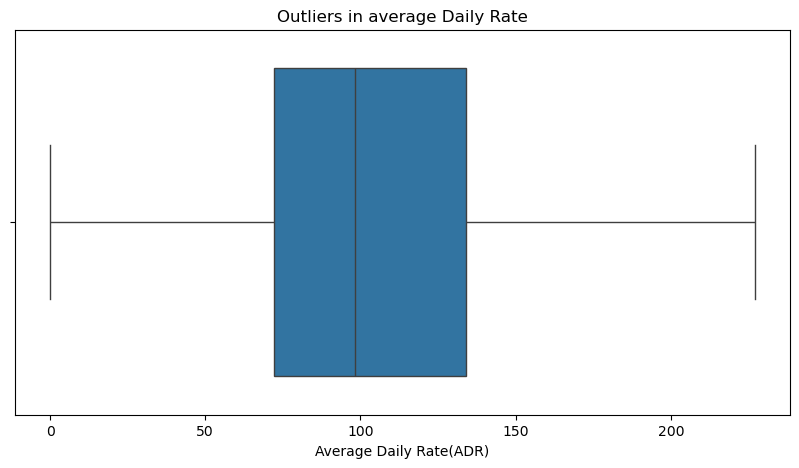

In [52]:
# Visualizing Outlier
plt.figure(figsize=(10,5))
sns.boxplot(x=df['adr'])
plt.title("Outliers in average Daily Rate")
plt.xlabel("Average Daily Rate(ADR)")
plt.show()

In [53]:
# Using IQR Method to clean it
Q1=df['adr'].quantile(0.25)
Q3=df['adr'].quantile(0.75)
IQR =Q3-Q1
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

outliers = df[
    (df['adr'] < lower_limit) |
    (df['adr'] > upper_limit)
]

print("Total Outliers:", len(outliers))

Lower Limit: -21.0
Upper Limit: 227.0
Total Outliers: 0


In [54]:
# Handling Outlier by caapimg extreme
df['adr'] = df['adr'].clip(
    lower=max(0, lower_limit),
    upper=upper_limit
)

print("Outliers handled successfully!")

Outliers handled successfully!


In [55]:
# Convert arrival year, day and week to integers
df['arrival_date_year'] = df['arrival_date_year'].astype(int)

df['arrival_date_day_of_month'] = df[
    'arrival_date_day_of_month'
].astype(int)

# Convert reservation status date
df['reservation_status_date'] = pd.to_datetime(
    df['reservation_status_date'],
    errors='coerce'
)

print(df.dtypes)

hotel                                     object
is_canceled                                int64
lead_time                                  int64
arrival_date_year                          int64
arrival_date_month                        object
arrival_date_week_number                   int64
arrival_date_day_of_month                  int64
stays_in_weekend_nights                    int64
stays_in_week_nights                       int64
adults                                     int64
children                                 float64
babies                                     int64
meal                                      object
country                                   object
market_segment                            object
distribution_channel                      object
is_repeated_guest                          int64
previous_cancellations                     int64
previous_bookings_not_canceled             int64
reserved_room_type                        object
assigned_room_type  

In [56]:
# Proper Arrival Date
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'] + '-' +
    df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d',
    errors='coerce'
)

print(df[['arrival_date', 'arrival_date_year']].head())

  arrival_date  arrival_date_year
0   2015-07-01               2015
1   2015-07-01               2015
2   2015-07-01               2015
3   2015-07-01               2015
4   2015-07-01               2015


In [57]:
# Creating New Features
# 1. Total guests
df['total_guests'] = (
    df['adults'] + df['children'] + df['babies']
)

# 2. Total nights
df['total_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

# 3. Is family booking
df['is_family'] = (
    (df['children'] > 0) | (df['babies'] > 0)
).astype(int)

# 4. Has special requests
df['has_special_requests'] = (
    df['total_of_special_requests'] > 0
).astype(int)

# 5. Weekend stay
df['has_weekend_stay'] = (
    df['stays_in_weekend_nights'] > 0
).astype(int)

# 6. Booking month number
df['booking_month'] = df['arrival_date'].dt.month

# 7. Total room revenue (estimated)
df['estimated_room_revenue'] = (
    df['adr'] * df['total_nights']
)

print("New features created successfully!")

df.head()

New features created successfully!


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,reservation_status,reservation_status_date,arrival_date,total_guests,total_nights,is_family,has_special_requests,has_weekend_stay,booking_month,estimated_room_revenue
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Check-Out,2015-07-01,2015-07-01,2.0,0,0,0,0,7,0.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Check-Out,2015-07-01,2015-07-01,2.0,0,0,0,0,7,0.0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Check-Out,2015-07-02,2015-07-01,1.0,1,0,0,0,7,75.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Check-Out,2015-07-02,2015-07-01,1.0,1,0,0,0,7,75.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Check-Out,2015-07-03,2015-07-01,2.0,2,0,1,0,7,196.0


In [58]:
# Categorical Variable
categorical_columns = df.select_dtypes(
    include=['object']
).columns

df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Categorical variables encoded!")
print("New Shape:", df_encoded.shape)

df_encoded.head()

Categorical variables encoded!
New Shape: (87396, 260)


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,assigned_room_type_K,assigned_room_type_L,assigned_room_type_P,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,reservation_status_Check-Out,reservation_status_No-Show
0,0,342,2015,27,1,0,0,2,0.0,0,...,0,0,0,0,0,0,1,0,1,0
1,0,737,2015,27,1,0,0,2,0.0,0,...,0,0,0,0,0,0,1,0,1,0
2,0,7,2015,27,1,0,1,1,0.0,0,...,0,0,0,0,0,0,1,0,1,0
3,0,13,2015,27,1,0,1,1,0.0,0,...,0,0,0,0,0,0,1,0,1,0
4,0,14,2015,27,1,0,2,2,0.0,0,...,0,0,0,0,0,0,1,0,1,0


In [59]:
# Normalize Numerical Features
# Select numerical columns
numerical_columns = df_encoded.select_dtypes(
    include=np.number
).columns.tolist()

# Exclude identifiers and date components where scaling is not useful
exclude_columns = [
    'agent',
    'company',
    'arrival_date_year',
    'arrival_date_week_number',
    'arrival_date_day_of_month',
    'booking_month'
]

scale_columns = [
    col for col in numerical_columns
    if col not in exclude_columns
]

scaler = StandardScaler()

df_encoded[scale_columns] = scaler.fit_transform(
    df_encoded[scale_columns]
)

print("Numerical features standardized successfully!")

Numerical features standardized successfully!


In [64]:
#Generating statistics for preprocessing
print("AFTER DATA CLEANING")

print(df.describe())

print("\nMissing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("\nEncoded Dataset Shape:", df_encoded.shape)

AFTER DATA CLEANING
        is_canceled     lead_time  arrival_date_year  \
count  87396.000000  87396.000000       87396.000000   
mean       0.274898     79.891368        2016.210296   
min        0.000000      0.000000        2015.000000   
25%        0.000000     11.000000        2016.000000   
50%        0.000000     49.000000        2016.000000   
75%        1.000000    125.000000        2017.000000   
max        1.000000    737.000000        2017.000000   
std        0.446466     86.052325           0.686102   

       arrival_date_week_number  arrival_date_day_of_month  \
count              87396.000000               87396.000000   
mean                  26.838334                  15.815541   
min                    1.000000                   1.000000   
25%                   16.000000                   8.000000   
50%                   27.000000                  16.000000   
75%                   37.000000                  23.000000   
max                   53.000000          

In [65]:
# Before After Cleaning
comparison = pd.DataFrame({
    'Before Cleaning': [
        original_shape[0],
        original_shape[1],
        original_missing,
        original_duplicates
    ],
    'After Cleaning': [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
}, index=[
    'Rows',
    'Columns',
    'Missing Values',
    'Duplicate Records'
])

print(comparison)

                   Before Cleaning  After Cleaning
Rows                         87396           87396
Columns                         40              40
Missing Values                   0               0
Duplicate Records               11              11


In [66]:
original_shape = df.shape
original_missing = df.isnull().sum().sum()
original_duplicates = df.duplicated().sum()

In [ ]:
# Save cleaned dataset
df.to_csv("Hotel_Booking_Cleaned.csv", index=False)

# Save encoded and standardized dataset
df_encoded.to_csv(
    "Hotel_Booking_Encoded_Standardized.csv",
    index=False
)

print("Both datasets saved successfully!")

In [ ]:
# Bonus Auto pipeling
# Separate numerical and categorical columns
X = df.drop(columns=['is_canceled', 'arrival_date'], errors='ignore')

num_features = X.select_dtypes(
    include=np.number
).columns.tolist()

cat_features = X.select_dtypes(
    include=['object']
).columns.tolist()

# Numerical preprocessing
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
])

# Apply preprocessing
X_processed = preprocessor.fit_transform(X)

print("Automated preprocessing completed!")
print("Processed Shape:", X_processed.shape)